# Objectives

1. Optimize hyperparameters of XGBoost, Random Forest, LightGBM, and CatBoost.
2. Use Optuna to search for better parameter combinations.
3. Apply time-based cross-validation.
4. Focus on PR-AUC due to class imbalance.
5. Track optimization trials and results using MLflow and DagsHub.
6. Compare tuned models using the validation dataset.
7. Select the final model and operating threshold before test evaluation.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Machine Learning libraries
import optuna
import mlflow
import dagshub

from sklearn.metrics import average_precision_score
from sklearn.model_selection import TimeSeriesSplit

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

# Project configuration
PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# DagsHub configuration
REPO_OWNER = "krishnagupta96321"
REPO_NAME = "Sentinel-risk-engine"

# Initialize DagsHub and MLflow
dagshub.init(repo_owner=REPO_OWNER,repo_name=REPO_NAME,mlflow=True)

# Create a separate MLflow experiment
mlflow.set_experiment("02_Hyperparameter_Optimization")

print("Project root:", PROJECT_ROOT)
print("Optuna version:", optuna.__version__)
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Active experiment: 02_Hyperparameter_Optimization")

Accessing as krishnagupta96321

Initialized MLflow to track repo "krishnagupta96321/Sentinel-risk-engine"

Repository krishnagupta96321/Sentinel-risk-engine initialized!

2026/11/04 17:58:45 INFO mlflow.tracking.fluent: Experiment with name '02_Hyperparameter_Optimization' does not exist. Creating a new experiment.


Project root: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine
Optuna version: 5.0.0
MLflow tracking URI: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow
Active experiment: 02_Hyperparameter_Optimization


In [2]:
# Load engineered dataset from Notebook 03
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "fraud_features.parquet"

df = pd.read_parquet(DATA_PATH)

# Remove unnecessary columns if present
drop_cols = [
    col for col in ["Unnamed: 0", ""]
    if col in df.columns
]

if drop_cols:
    df.drop(columns=drop_cols, inplace=True)

# Ensure chronological ordering
if not df["unix_time"].is_monotonic_increasing:
    df = df.sort_values("unix_time").reset_index(drop=True)

# Recreate the same chronological 70:15:15 split
total_rows = len(df)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

target_col = "is_fraud"

static_features = [
    "amt",
    "log_amt",
    "city_pop",
    "haversine_dist_km",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "is_weekend"
]

velocity_features = static_features + [
    "tx_count_1h",
    "tx_sum_1h",
    "tx_count_24h",
    "tx_sum_24h"
]


required_columns = velocity_features + [target_col, "unix_time"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Display dataset information
print("Dataset shape:", df.shape)

print(f"\nTraining rows: {len(train_df):,}")
print(f"Validation rows: {len(val_df):,}")
print(f"Test rows: {len(test_df):,}")

print("\nFeature configuration:")
print("Static features:", len(static_features))
print("Static + Velocity features:", len(velocity_features))

print("\nFraud distribution:")
for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {split[target_col].mean() * 100:.3f}% "
        f"fraud rate"
    )

print("\nChronological boundaries:")
print("Train ends:", train_df["unix_time"].max())
print("Validation ends:", val_df["unix_time"].max())
print("Test ends:", test_df["unix_time"].max())

Dataset shape: (1296675, 34)

Training rows: 907,672
Validation rows: 194,501
Test rows: 194,502

Feature configuration:
Static features: 9
Static + Velocity features: 13

Fraud distribution:
Train: 0.564% fraud rate
Validation: 0.644% fraud rate
Test: 0.583% fraud rate

Chronological boundaries:
Train ends: 1356715104
Validation ends: 1365011632
Test ends: 1371816817


## 1. Time-Aware Cross-Validation Setup


Evaluating  ML  model using multiple train-validation splits while maintaining chronological order(arranging data according to when an event happened, from oldest to newest).

# 1.1 Configure Expanding-Window TimeSeriesSplit

setting up a cross-validation technique where the training dataset gradually increases in size, while the validation dataset moves forward in time.

In [3]:
from sklearn.model_selection import TimeSeriesSplit

# Configure chronological cross-validation
N_SPLITS = 5

tscv = TimeSeriesSplit(n_splits=N_SPLITS)

X_train = train_df[velocity_features]
y_train = train_df[target_col]

# Store fold information
fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train),start=1):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_results.append({
        "Fold": fold,
        "Train Rows": len(train_idx),
        "Validation Rows": len(val_idx),
        "Train Fraud Rate (%)": round(
            y_fold_train.mean() * 100, 4
        ),
        "Validation Fraud Rate (%)": round(
            y_fold_val.mean() * 100, 4
        )
    })

# Display cross-validation summary
fold_df = pd.DataFrame(fold_results)

fold_df

print(f"\nCross-validation strategy: Expanding Window")
print(f"Number of folds: {N_SPLITS}")
print("Shuffling: Disabled")
print("Data used: Training dataset only")


Cross-validation strategy: Expanding Window
Number of folds: 5
Shuffling: Disabled
Data used: Training dataset only


## 04. XGBoost Hyperparameter Optimization

In [4]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score


X_train_opt = train_df[velocity_features]
y_train_opt = train_df[target_col]

def xgb_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1200
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "gamma": trial.suggest_float(
            "gamma", 0, 5
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0, 10
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0, 10
        ),
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "tree_method": "hist",
        "random_state": 42,
        "n_jobs": -1
    }

    fold_scores = []

    # Create nested MLflow run for this Optuna trial
    with mlflow.start_run(nested=True,run_name=f"xgb_trial_{trial.number}"):

        mlflow.log_params(params)
        mlflow.log_param("feature_set", "static_velocity")
        mlflow.log_param("cv_folds", N_SPLITS)

        # Five-fold chronological cross-validation
        for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_opt),start=1):

            X_fold_train = X_train_opt.iloc[train_idx]
            X_fold_val = X_train_opt.iloc[val_idx]

            y_fold_train = y_train_opt.iloc[train_idx]
            y_fold_val = y_train_opt.iloc[val_idx]

            # Calculate class imbalance from fold training data
            scale_pos_weight = (
                (y_fold_train == 0).sum() /
                (y_fold_train == 1).sum()
            )

            fold_params = params.copy()
            fold_params["scale_pos_weight"] = scale_pos_weight

            # Train model
            model = XGBClassifier(**fold_params)

            model.fit(X_fold_train,y_fold_train,verbose=False)

            # Predict validation probabilities
            val_probs = model.predict_proba(X_fold_val)[:, 1]

            # Calculate PR-AUC
            fold_pr_auc = average_precision_score( y_fold_val,val_probs)

            fold_scores.append(fold_pr_auc)

            mlflow.log_metric(f"fold_{fold}_pr_auc",float(fold_pr_auc))

        # Calculate mean cross-validation PR-AUC
        mean_pr_auc = float(np.mean(fold_scores))

        mlflow.log_metric("mean_cv_pr_auc",mean_pr_auc)

        mlflow.log_metric("std_cv_pr_auc",float(np.std(fold_scores)))

        # Store fold results in Optuna
        trial.set_user_attr("fold_scores",fold_scores)

        print(
            f"Trial {trial.number} | "
            f"Mean CV PR-AUC: {mean_pr_auc:.5f}"
        )

    return mean_pr_auc


print("XGBoost Optuna objective function defined.")
print("Feature set: Static + Velocity")
print("Optimization metric: Mean 5-fold CV PR-AUC")

XGBoost Optuna objective function defined.
Feature set: Static + Velocity
Optimization metric: Mean 5-fold CV PR-AUC


In [5]:
# Configure Optuna logging
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Create Optuna study
study_xgb = optuna.create_study(
    study_name="XGBoost_Static_Velocity_Optimization",direction="maximize",sampler=optuna.samplers.TPESampler(seed=42))

# Number of optimization trials
N_TRIALS = 20

# Start parent MLflow run
with mlflow.start_run(run_name="XGBoost_Optuna_Optimization") as parent_run:

    xgb_parent_run_id = parent_run.info.run_id

    # Log optimization configuration
    mlflow.log_params({
        "model": "XGBoost",
        "feature_set": "static_velocity",
        "optimization_metric": "mean_cv_pr_auc",
        "cv_strategy": "TimeSeriesSplit",
        "cv_folds": N_SPLITS,
        "n_trials": N_TRIALS,
        "sampler": "TPESampler",
        "random_seed": 42
    })

    # Execute Optuna optimization
    study_xgb.optimize(xgb_objective,n_trials=N_TRIALS,show_progress_bar=True)

    # Capture best trial
    best_trial_xgb = study_xgb.best_trial

    best_xgb_params = best_trial_xgb.params
    best_xgb_pr_auc = best_trial_xgb.value

    # Log best results to parent MLflow run
    mlflow.log_params({
        f"best_{key}": value
        for key, value in best_xgb_params.items()
    })

    mlflow.log_metric(
        "best_cv_pr_auc",
        float(best_xgb_pr_auc)
    )

    mlflow.log_param(
        "best_trial_number",
        best_trial_xgb.number
    )

print("\nXGBoost Optimization Completed")
print("Total trials:", len(study_xgb.trials))
print("Best trial:", best_trial_xgb.number)
print(f"Best Mean CV PR-AUC: {best_xgb_pr_auc:.5f}")

print("\nBest Hyperparameters:")
for param, value in best_xgb_params.items():
    print(f"{param}: {value}")

print("\nParent MLflow Run ID:", xgb_parent_run_id)

  0%|          | 0/20 [00:00<?, ?it/s]

Trial 0 | Mean CV PR-AUC: 0.84288
🏃 View run xgb_trial_0 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/d99ed8fff400492988d4f17893f14288
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 1 | Mean CV PR-AUC: 0.82667
🏃 View run xgb_trial_1 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/a2a63ef5129a485fa6d66f8c3b669075
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 2 | Mean CV PR-AUC: 0.84441
🏃 View run xgb_trial_2 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/098267e503b546218790da71d3deb4c8
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 3 | Mean CV PR-AUC: 0.85260
🏃 View run xgb_trial_3 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/ru

In [6]:
# Create reports directory
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Reports directory:", REPORTS_DIR)

Reports directory: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports


In [7]:
# Optimization Results & Visualization


import optuna.visualization as vis

# Create optimization history plot
fig_history = vis.plot_optimization_history(study_xgb,target_name="Mean CV PR-AUC")

fig_history.show()

# Create hyperparameter importance plot
fig_importance = vis.plot_param_importances( study_xgb,target_name="Mean CV PR-AUC")

fig_importance.show()

# Create trial results DataFrame
trials_df = study_xgb.trials_dataframe()

# Display trial results
trials_df[["number", "value", "state"]].sort_values(by="value",ascending=False)


# Save trial results
trials_path = REPORTS_DIR / "xgboost_optuna_trials.csv"
trials_df.to_csv(trials_path, index=False)

# Log results and visualizations to parent MLflow run
with mlflow.start_run(run_id=xgb_parent_run_id):

    mlflow.log_artifact(
        str(trials_path),
        artifact_path="optimization_results"
    )

    mlflow.log_figure(
        fig_history,
        "optimization_results/optimization_history.html"
    )

    mlflow.log_figure(
        fig_importance,
        "optimization_results/parameter_importance.html"
    )

print("Optimization results saved and logged to MLflow.")
print("Best trial:", study_xgb.best_trial.number)
print("Best CV PR-AUC:", study_xgb.best_value)

🏃 View run XGBoost_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/9e2ec7c4658348bdade5566c8c3b8685
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Optimization results saved and logged to MLflow.
Best trial: 16
Best CV PR-AUC: 0.8528823627540791


# 5. Train Best XGBoost Model & Evaluate on Validation Data

In [8]:
from sklearn.metrics import average_precision_score,roc_auc_score,brier_score_loss

# Prepare training and validation datasets
X_train_xgb_best = train_df[velocity_features]
X_val_xgb_best = val_df[velocity_features]

y_train_xgb_best = train_df[target_col]
y_val_xgb_best = val_df[target_col]

# Calculate class imbalance using training data only
scale_pos_weight = ((y_train_xgb_best == 0).sum() /(y_train_xgb_best == 1).sum())

# Configure optimized XGBoost parameters
final_xgb_params = {
    **best_xgb_params,
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "tree_method": "hist",
    "scale_pos_weight": scale_pos_weight,
    "random_state": 42,
    "n_jobs": -1
}

# Train optimized XGBoost model
best_xgb_model = XGBClassifier(**final_xgb_params)

best_xgb_model.fit(X_train_xgb_best,y_train_xgb_best,verbose=False)

# Generate validation probabilities
best_xgb_val_probs = best_xgb_model.predict_proba(X_val_xgb_best)[:, 1]

# Calculate validation metrics
best_xgb_val_metrics = {
    "pr_auc": average_precision_score(
        y_val_xgb_best, best_xgb_val_probs
    ),
    "roc_auc": roc_auc_score(
        y_val_xgb_best, best_xgb_val_probs
    ),
    "brier_score": brier_score_loss(
        y_val_xgb_best, best_xgb_val_probs
    )
}

# Log model and metrics to parent MLflow run
with mlflow.start_run(run_id=xgb_parent_run_id):

    mlflow.log_metrics({
        f"val_{metric}": float(value)
        for metric, value in best_xgb_val_metrics.items()
    })

    mlflow.xgboost.log_model(
        best_xgb_model,
        artifact_path="best_xgb_model"
    )

# Display results
print("Optimized XGBoost — Validation Results")


for metric, value in best_xgb_val_metrics.items():
    print(f"{metric.upper()}: {value:.5f}")

print("\nBest Optuna Trial:", best_trial_xgb.number)
print("Best CV PR-AUC:", round(best_xgb_pr_auc, 5))
print("Optimized model logged to MLflow.")

2026/11/05 18:03:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run XGBoost_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/9e2ec7c4658348bdade5566c8c3b8685
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Optimized XGBoost — Validation Results
PR_AUC: 0.88674
ROC_AUC: 0.99686
BRIER_SCORE: 0.00874

Best Optuna Trial: 16
Best CV PR-AUC: 0.85288
Optimized model logged to MLflow.


# 06. Random Forest Hyperparameter Optimization

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Prepare Static + Velocity features
X_train_rf_opt = train_df[velocity_features]
y_train_rf_opt = train_df[target_col]

# Define Random Forest objective
def rf_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 800, step=100
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 10, 40
        ),
        "min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 20
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),
        "max_features": trial.suggest_categorical(
            "max_features", ["sqrt", "log2", 0.8]
        ),
        "class_weight": "balanced_subsample",
        "random_state": 42,
        "n_jobs": -1
    }

    fold_scores = []

    # Nested MLflow run for each trial
    with mlflow.start_run(nested=True,run_name=f"rf_trial_{trial.number}"):

        mlflow.log_params(params)
        mlflow.log_param("feature_set", "static_velocity")
        mlflow.log_param("cv_folds", N_SPLITS)

        # Five-fold chronological CV
        for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_rf_opt),start=1):

            X_fold_train = X_train_rf_opt.iloc[train_idx]
            X_fold_val = X_train_rf_opt.iloc[val_idx]

            y_fold_train = y_train_rf_opt.iloc[train_idx]
            y_fold_val = y_train_rf_opt.iloc[val_idx]

            # Train Random Forest
            model = RandomForestClassifier(**params)

            model.fit(X_fold_train,y_fold_train)

            # Validation probabilities
            val_probs = model.predict_proba(X_fold_val)[:, 1]

            # Calculate PR-AUC
            fold_pr_auc = average_precision_score(y_fold_val,val_probs)

            fold_scores.append(fold_pr_auc)

            mlflow.log_metric(f"fold_{fold}_pr_auc",float(fold_pr_auc))

        # Calculate mean CV PR-AUC
        mean_pr_auc = float(np.mean(fold_scores))

        mlflow.log_metric(
            "mean_cv_pr_auc",
            mean_pr_auc)

        mlflow.log_metric(
            "std_cv_pr_auc",
            float(np.std(fold_scores))
        )

        trial.set_user_attr("fold_scores",fold_scores)

        print(
            f"Trial {trial.number} | "
            f"Mean CV PR-AUC: {mean_pr_auc:.5f}"
        )

    return mean_pr_auc


print("Random Forest Optuna objective function defined.")
print("Feature set: Static + Velocity")
print("Optimization metric: Mean 5-fold CV PR-AUC")

Random Forest Optuna objective function defined.
Feature set: Static + Velocity
Optimization metric: Mean 5-fold CV PR-AUC


In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study_rf = optuna.create_study(study_name="RandomForest_Static_Velocity_Optimization",
    direction="maximize",sampler=optuna.samplers.TPESampler(seed=42))

N_TRIALS_RF = 10

with mlflow.start_run(run_name="RandomForest_Optuna_Optimization") as parent_run:

    rf_parent_run_id = parent_run.info.run_id

    mlflow.log_params({
        "model": "RandomForest",
        "feature_set": "static_velocity",
        "optimization_metric": "mean_cv_pr_auc",
        "cv_folds": N_SPLITS,
        "n_trials": N_TRIALS_RF
    })

    study_rf.optimize(rf_objective,n_trials=N_TRIALS_RF,show_progress_bar=True)

    best_trial_rf = study_rf.best_trial
    best_rf_params = best_trial_rf.params
    best_rf_pr_auc = best_trial_rf.value

    mlflow.log_params({
        f"best_{key}": value
        for key, value in best_rf_params.items()})

    mlflow.log_metric("best_cv_pr_auc", float(best_rf_pr_auc))
    mlflow.log_param("best_trial_number", best_trial_rf.number)

print("\nRandom Forest Optimization Completed")
print("Best Trial:", best_trial_rf.number)
print("Best Mean CV PR-AUC:", round(best_rf_pr_auc, 5))
print("\nBest Hyperparameters:")
print(best_rf_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Trial 0 | Mean CV PR-AUC: 0.84102
🏃 View run rf_trial_0 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/475dd830cfc1477ba37a2046a897ead0
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 1 | Mean CV PR-AUC: 0.83838
🏃 View run rf_trial_1 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/5b74fa70ced9438194df49c280ce5867
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 2 | Mean CV PR-AUC: 0.81909
🏃 View run rf_trial_2 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/827605328def4926b2c7c3d30b661f5c
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 3 | Mean CV PR-AUC: 0.83838
🏃 View run rf_trial_3 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/c

# Optimization Results & Visualization

In [12]:
# Generate Optuna optimization history
fig_rf_history = optuna.visualization.plot_optimization_history(study_rf,target_name="Mean CV PR-AUC")

fig_rf_history.show()

# Generate hyperparameter importance
fig_rf_importance = optuna.visualization.plot_param_importances(study_rf,target_name="Mean CV PR-AUC")

fig_rf_importance.show()

# Convert trial results into a DataFrame
rf_trials_df = study_rf.trials_dataframe()

rf_trials_df

# Save trial results
rf_trials_path = REPORTS_DIR / "random_forest_optuna_trials.csv"
rf_trials_df.to_csv(rf_trials_path, index=False)

# Log results and visualizations to MLflow
with mlflow.start_run(run_id=rf_parent_run_id):
    mlflow.log_artifact(str(rf_trials_path))
    mlflow.log_figure(
        fig_rf_history,
        "random_forest_optimization_history.html"
    )
    mlflow.log_figure(
        fig_rf_importance,
        "random_forest_parameter_importance.html"
    )

print("Random Forest optimization results saved and logged.")

🏃 View run RandomForest_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/341d5ac17d7e47f0b4215397b26d7161
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Random Forest optimization results saved and logged.


 # Random forest training  and evaluation on validation data

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss)

# 1. Prepare training and validation data
X_train_rf_best = train_df[velocity_features]
X_val_rf_best = val_df[velocity_features]

y_train_rf_best = train_df[target_col]
y_val_rf_best = val_df[target_col]

# 2. Configure the best Random Forest model
final_rf_params = {
    **best_rf_params,
    "class_weight": "balanced_subsample",
    "random_state": 42,
    "n_jobs": -1
}

# 3. Train on the complete training dataset
best_rf_model = RandomForestClassifier(**final_rf_params)

best_rf_model.fit(X_train_rf_best,y_train_rf_best)

# 4. Generate validation probabilities
best_rf_val_probs = best_rf_model.predict_proba(X_val_rf_best)[:, 1]

# 5. Calculate validation metrics
best_rf_val_metrics = {
    "pr_auc": average_precision_score(
        y_val_rf_best, best_rf_val_probs
    ),
    "roc_auc": roc_auc_score(
        y_val_rf_best, best_rf_val_probs
    ),
    "brier_score": brier_score_loss(
        y_val_rf_best, best_rf_val_probs
    )
}

# 6. Log validation metrics and model to MLflow
with mlflow.start_run(run_id=rf_parent_run_id):

    mlflow.log_metrics({
        f"val_{metric}": float(value)
        for metric, value in best_rf_val_metrics.items()
    })

    mlflow.sklearn.log_model(best_rf_model,artifact_path="best_rf_model",skops_trusted_types=["sklearn.tree._tree.Tree"])

# 7. Display results
print("Random Forest Validation Results")

for metric, value in best_rf_val_metrics.items():
    print(f"{metric.upper()}: {value:.5f}")

print("\nBest Optuna Trial:", best_trial_rf.number)
print("Best CV PR-AUC:", round(best_rf_pr_auc, 5))
print("Model logged to MLflow.")

2026/11/06 12:56:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run RandomForest_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/341d5ac17d7e47f0b4215397b26d7161
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Random Forest Validation Results
PR_AUC: 0.88269
ROC_AUC: 0.99355
BRIER_SCORE: 0.00241

Best Optuna Trial: 0
Best CV PR-AUC: 0.84102
Model logged to MLflow.


# 07. LightGBM Hyperparameter Optimization

#

In [16]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score

# Prepare Static + Velocity features
X_train_lgb_opt = train_df[velocity_features]
y_train_lgb_opt = train_df[target_col]


# Define LightGBM Optuna objective
def lgb_objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1200
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 20, 150
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 4, 12
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 100
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "subsample_freq": 1,

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0.0, 10.0
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.0, 10.0
        ),
        "class_weight": "balanced",
        "objective": "binary",
        "verbosity": -1,
        "random_state": 42,
        "n_jobs": -1
    }

    fold_scores = []

    with mlflow.start_run(nested=True,run_name=f"lgb_trial_{trial.number}"):

        mlflow.log_params(params)
        mlflow.log_param("feature_set", "static_velocity")
        mlflow.log_param("cv_folds", N_SPLITS)

        for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_lgb_opt), start=1):

            X_fold_train = X_train_lgb_opt.iloc[train_idx]
            X_fold_val = X_train_lgb_opt.iloc[val_idx]

            y_fold_train = y_train_lgb_opt.iloc[train_idx]
            y_fold_val = y_train_lgb_opt.iloc[val_idx]

            model = LGBMClassifier(**params)

            model.fit(X_fold_train,y_fold_train)

            val_probs = model.predict_proba(X_fold_val)[:, 1]

            fold_pr_auc = average_precision_score(y_fold_val,val_probs)

            fold_scores.append(fold_pr_auc)

            mlflow.log_metric(
                f"fold_{fold}_pr_auc",
                float(fold_pr_auc)
            )

        mean_pr_auc = float(np.mean(fold_scores))

        mlflow.log_metric("mean_cv_pr_auc", mean_pr_auc)
        mlflow.log_metric("std_cv_pr_auc",float(np.std(fold_scores)))

        trial.set_user_attr("fold_scores", fold_scores)

        print(
            f"Trial {trial.number} | "
            f"Mean CV PR-AUC: {mean_pr_auc:.5f}"
        )

    return mean_pr_auc


print("LightGBM Optuna objective function defined.")
print("Feature set: Static + Velocity")
print("Optimization metric: Mean 5-fold CV PR-AUC")

LightGBM Optuna objective function defined.
Feature set: Static + Velocity
Optimization metric: Mean 5-fold CV PR-AUC


In [17]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study_lgb = optuna.create_study(
    study_name="LightGBM_Static_Velocity_Optimization",direction="maximize",sampler=optuna.samplers.TPESampler(seed=42))

N_TRIALS_LGB = 10

with mlflow.start_run(run_name="LightGBM_Optuna_Optimization") as parent_run:

    lgb_parent_run_id = parent_run.info.run_id

    mlflow.log_params({
        "model": "LightGBM",
        "feature_set": "static_velocity",
        "optimization_metric": "mean_cv_pr_auc",
        "cv_folds": N_SPLITS,
        "n_trials": N_TRIALS_LGB
    })

    study_lgb.optimize(lgb_objective,n_trials=N_TRIALS_LGB,show_progress_bar=True)

    best_trial_lgb = study_lgb.best_trial
    best_lgb_params = best_trial_lgb.params
    best_lgb_pr_auc = best_trial_lgb.value

    mlflow.log_params({
        f"best_{key}": value
        for key, value in best_lgb_params.items()
    })

    mlflow.log_metric(
        "best_cv_pr_auc",
        float(best_lgb_pr_auc)
    )

    mlflow.log_param(
        "best_trial_number",
        best_trial_lgb.number
    )

print("\nLightGBM Optimization Completed")
print("Best Trial:", best_trial_lgb.number)
print("Best Mean CV PR-AUC:", round(best_lgb_pr_auc, 5))
print("\nBest Hyperparameters:")
print(best_lgb_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Trial 0 | Mean CV PR-AUC: 0.84047
🏃 View run lgb_trial_0 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/54561b3435a64525aeea130195e36a6c
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 1 | Mean CV PR-AUC: 0.85232
🏃 View run lgb_trial_1 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/1387f4c428414441ad89c37057ee21a5
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 2 | Mean CV PR-AUC: 0.85156
🏃 View run lgb_trial_2 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/10212112945f4deab641f186fc66fb75
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 3 | Mean CV PR-AUC: 0.84345
🏃 View run lgb_trial_3 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/ru

# Optuna Results & Visualization

In [18]:
# Generate optimization history
fig_lgb_history = optuna.visualization.plot_optimization_history(study_lgb,target_name="Mean CV PR-AUC")

fig_lgb_history.show()

# Generate hyperparameter importance
fig_lgb_importance = optuna.visualization.plot_param_importances(study_lgb,target_name="Mean CV PR-AUC")

fig_lgb_importance.show()

# Convert trial results into DataFrame
lgb_trials_df = study_lgb.trials_dataframe()

lgb_trials_df

# Save trial results
lgb_trials_path = REPORTS_DIR / "lightgbm_optuna_trials.csv"
lgb_trials_df.to_csv(lgb_trials_path, index=False)

# Log results to MLflow
with mlflow.start_run(run_id=lgb_parent_run_id):

    mlflow.log_artifact(str(lgb_trials_path))

    mlflow.log_figure(
        fig_lgb_history,
        "lightgbm_optimization_history.html"
    )

    mlflow.log_figure(
        fig_lgb_importance,
        "lightgbm_parameter_importance.html"
    )

print("LightGBM optimization results saved and logged.")

🏃 View run LightGBM_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/37f34915841f48ca972aa9d3a575a60e
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
LightGBM optimization results saved and logged.


In [19]:
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss)

# Prepare training and validation data
X_train_lgb_best = train_df[velocity_features]
X_val_lgb_best = val_df[velocity_features]

y_train_lgb_best = train_df[target_col]
y_val_lgb_best = val_df[target_col]

# Configure best LightGBM model
final_lgb_params = {
    **best_lgb_params,
    "subsample_freq": 1,
    "class_weight": "balanced",
    "objective": "binary",
    "verbosity": -1,
    "random_state": 42,
    "n_jobs": -1
}

# Train on complete training data
best_lgb_model = LGBMClassifier(**final_lgb_params)
best_lgb_model.fit(X_train_lgb_best, y_train_lgb_best)

# Generate validation probabilities
best_lgb_val_probs = best_lgb_model.predict_proba(X_val_lgb_best)[:, 1]

# Calculate validation metrics
best_lgb_val_metrics = {
    "pr_auc": average_precision_score(
        y_val_lgb_best, best_lgb_val_probs
    ),
    "roc_auc": roc_auc_score(
        y_val_lgb_best, best_lgb_val_probs
    ),
    "brier_score": brier_score_loss(
        y_val_lgb_best, best_lgb_val_probs
    )
}

# Log metrics and trained model to MLflow
with mlflow.start_run(run_id=lgb_parent_run_id):

    mlflow.log_metrics({
        f"val_{metric}": float(value)
        for metric, value in best_lgb_val_metrics.items()
    })

    mlflow.lightgbm.log_model(best_lgb_model,artifact_path="best_lgb_model")

# Display results
print("LightGBM Validation Results")

for metric, value in best_lgb_val_metrics.items():
    print(f"{metric.upper()}: {value:.5f}")

print("\nBest Optuna Trial:", best_trial_lgb.number)
print("Best CV PR-AUC:", round(best_lgb_pr_auc, 5))
print("Model logged to MLflow.")

2026/11/06 13:28:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run LightGBM_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/37f34915841f48ca972aa9d3a575a60e
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
LightGBM Validation Results
PR_AUC: 0.89036
ROC_AUC: 0.99696
BRIER_SCORE: 0.00714

Best Optuna Trial: 1
Best CV PR-AUC: 0.85232
Model logged to MLflow.


# 8. CatBoost Hyperparameter Optimization

In [20]:
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score

# Prepare Static + Velocity features
X_train_cat_opt = train_df[velocity_features]
y_train_cat_opt = train_df[target_col]


def cat_objective(trial):

    params = {
        "iterations": trial.suggest_int(
            "iterations", 500, 1500
        ),
        "depth": trial.suggest_int(
            "depth", 4, 10
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1.0, 10.0
        ),
        "random_strength": trial.suggest_float(
            "random_strength", 0.1, 5.0
        ),
        "border_count": trial.suggest_int(
            "border_count", 32, 128
        ),
        "loss_function": "Logloss",
        "eval_metric": "PRAUC",
        "auto_class_weights": "Balanced",
        "random_seed": 42,
        "verbose": False,
        "thread_count": -1,
        "allow_writing_files": False
    }

    fold_scores = []

    with mlflow.start_run(nested=True,run_name=f"cat_trial_{trial.number}"):

        mlflow.log_params(params)
        mlflow.log_param("feature_set", "static_velocity")
        mlflow.log_param("cv_folds", N_SPLITS)

        for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_cat_opt), start=1):

            X_fold_train = X_train_cat_opt.iloc[train_idx]
            X_fold_val = X_train_cat_opt.iloc[val_idx]

            y_fold_train = y_train_cat_opt.iloc[train_idx]
            y_fold_val = y_train_cat_opt.iloc[val_idx]

            model = CatBoostClassifier(**params)

            model.fit(X_fold_train,y_fold_train)

            val_probs = model.predict_proba(X_fold_val)[:, 1]

            fold_pr_auc = average_precision_score(y_fold_val,val_probs)

            fold_scores.append(fold_pr_auc)

            mlflow.log_metric(
                f"fold_{fold}_pr_auc",
                float(fold_pr_auc)
            )

        mean_pr_auc = float(np.mean(fold_scores))

        mlflow.log_metric("mean_cv_pr_auc", mean_pr_auc)
        mlflow.log_metric(
            "std_cv_pr_auc",
            float(np.std(fold_scores))
        )

        trial.set_user_attr("fold_scores", fold_scores)

        print(
            f"Trial {trial.number} | "
            f"Mean CV PR-AUC: {mean_pr_auc:.5f}"
        )

    return mean_pr_auc


print("CatBoost Optuna objective function defined.")
print("Feature set: Static + Velocity")
print("Optimization metric: Mean 5-fold CV PR-AUC")

CatBoost Optuna objective function defined.
Feature set: Static + Velocity
Optimization metric: Mean 5-fold CV PR-AUC


In [21]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study_cat = optuna.create_study(study_name="CatBoost_Static_Velocity_Optimization",direction="maximize",sampler=optuna.samplers.TPESampler(seed=42))

N_TRIALS_CAT = 5

with mlflow.start_run(run_name="CatBoost_Optuna_Optimization") as parent_run:

    cat_parent_run_id = parent_run.info.run_id

    mlflow.log_params({
        "model": "CatBoost",
        "feature_set": "static_velocity",
        "optimization_metric": "mean_cv_pr_auc",
        "cv_folds": N_SPLITS,
        "n_trials": N_TRIALS_CAT
    })

    study_cat.optimize(cat_objective,n_trials=N_TRIALS_CAT,show_progress_bar=True)

    best_trial_cat = study_cat.best_trial
    best_cat_params = best_trial_cat.params
    best_cat_pr_auc = best_trial_cat.value

    mlflow.log_params({
        f"best_{key}": value
        for key, value in best_cat_params.items()
    })

    mlflow.log_metric(
        "best_cv_pr_auc",
        float(best_cat_pr_auc)
    )

    mlflow.log_param(
        "best_trial_number",
        best_trial_cat.number
    )

print("\nCatBoost Optimization Completed")
print("Best Trial:", best_trial_cat.number)
print("Best Mean CV PR-AUC:", round(best_cat_pr_auc, 5))
print("\nBest Hyperparameters:")
print(best_cat_params)

  0%|          | 0/5 [00:00<?, ?it/s]

Trial 0 | Mean CV PR-AUC: 0.80584
🏃 View run cat_trial_0 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/097259bb8d38494a9173d8f2515cc1ce
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 1 | Mean CV PR-AUC: 0.83895
🏃 View run cat_trial_1 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/b52ff805f22a449dbe104122589e676e
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 2 | Mean CV PR-AUC: 0.81992
🏃 View run cat_trial_2 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/d0f0d1d64fdc488a9c8881c468b8b2fc
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Trial 3 | Mean CV PR-AUC: 0.80984
🏃 View run cat_trial_3 at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/ru

# Optuna Results & Visualization

In [22]:
# Generate optimization history
fig_cat_history = optuna.visualization.plot_optimization_history(study_cat,target_name="Mean CV PR-AUC")

fig_cat_history.show()

# Generate hyperparameter importance
fig_cat_importance = optuna.visualization.plot_param_importances(study_cat,target_name="Mean CV PR-AUC")

fig_cat_importance.show()

# Convert trial results into DataFrame
cat_trials_df = study_cat.trials_dataframe()

cat_trials_df

# Save trial results
cat_trials_path = REPORTS_DIR / "catboost_optuna_trials.csv"
cat_trials_df.to_csv(cat_trials_path, index=False)

# Log results to MLflow
with mlflow.start_run(run_id=cat_parent_run_id):

    mlflow.log_artifact(str(cat_trials_path))

    mlflow.log_figure(
        fig_cat_history,
        "catboost_optimization_history.html"
    )

    mlflow.log_figure(
        fig_cat_importance,
        "catboost_parameter_importance.html"
    )

print("CatBoost optimization results saved and logged.")

🏃 View run CatBoost_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/289cdad1775c45e1ba69378678fa01d8
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
CatBoost optimization results saved and logged.


# Training and Evaluation on Validation Data

In [23]:
from catboost import CatBoostClassifier
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss)

# 1. Prepare training and validation data
X_train_cat_best = train_df[velocity_features]
X_val_cat_best = val_df[velocity_features]

y_train_cat_best = train_df[target_col]
y_val_cat_best = val_df[target_col]

# 2. Configure the best CatBoost model
final_cat_params = {
    **best_cat_params,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "Balanced",
    "random_seed": 42,
    "verbose": False,
    "thread_count": -1,
    "allow_writing_files": False
}

# 3. Train on the complete training dataset
best_cat_model = CatBoostClassifier(**final_cat_params)

best_cat_model.fit(X_train_cat_best,y_train_cat_best)

# 4. Generate validation probabilities
best_cat_val_probs = best_cat_model.predict_proba(X_val_cat_best)[:, 1]

# 5. Calculate validation metrics
best_cat_val_metrics = {
    "pr_auc": average_precision_score(
        y_val_cat_best, best_cat_val_probs
    ),
    "roc_auc": roc_auc_score(
        y_val_cat_best, best_cat_val_probs
    ),
    "brier_score": brier_score_loss(
        y_val_cat_best, best_cat_val_probs
    )
}

# 6. Log metrics and model to MLflow
with mlflow.start_run(run_id=cat_parent_run_id):

    mlflow.log_metrics({
        f"val_{metric}": float(value)
        for metric, value in best_cat_val_metrics.items()
    })

    mlflow.catboost.log_model(
        best_cat_model,
        artifact_path="best_cat_model"
    )

# 7. Display results
print("CatBoost Validation Results")

for metric, value in best_cat_val_metrics.items():
    print(f"{metric.upper()}: {value:.5f}")

print("\nBest Optuna Trial:", best_trial_cat.number)
print("Best CV PR-AUC:", round(best_cat_pr_auc, 5))
print("Model logged to MLflow.")

2026/11/06 15:20:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run CatBoost_Optuna_Optimization at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/289cdad1775c45e1ba69378678fa01d8
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
CatBoost Validation Results
PR_AUC: 0.87519
ROC_AUC: 0.99487
BRIER_SCORE: 0.00488

Best Optuna Trial: 1
Best CV PR-AUC: 0.83895
Model logged to MLflow.


# 9. Final Comparison of Optimized Models

In [24]:
# Collect validation metrics from all four models

model_results = {
    "XGBoost": best_xgb_val_metrics,
    "Random Forest": best_rf_val_metrics,
    "LightGBM": best_lgb_val_metrics,
    "CatBoost": best_cat_val_metrics
}

comparison_df = pd.DataFrame.from_dict(model_results,orient="index")

comparison_df.index.name = "Model"

# Add CV PR-AUC scores
comparison_df["cv_pr_auc"] = [
    best_xgb_pr_auc,
    best_rf_pr_auc,
    best_lgb_pr_auc,
    best_cat_pr_auc
]

# Organize columns
comparison_df = comparison_df[["cv_pr_auc", "pr_auc", "roc_auc", "brier_score"]]

# Rename validation metric columns
comparison_df.rename(
    columns={
        "pr_auc": "validation_pr_auc",
        "roc_auc": "validation_roc_auc",
        "brier_score": "validation_brier_score"
    },
    inplace=True
)

# Sort by validation PR-AUC
comparison_df.sort_values(
    by="validation_pr_auc",
    ascending=False,
    inplace=True
)

comparison_df.round(5)

# Save comparison report
comparison_path = REPORTS_DIR / "optimized_model_comparison.csv"

comparison_df.to_csv(comparison_path)

print("Optimized model comparison saved:", comparison_path)

Optimized model comparison saved: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\optimized_model_comparison.csv


# 9.1 Visualize Model Performance

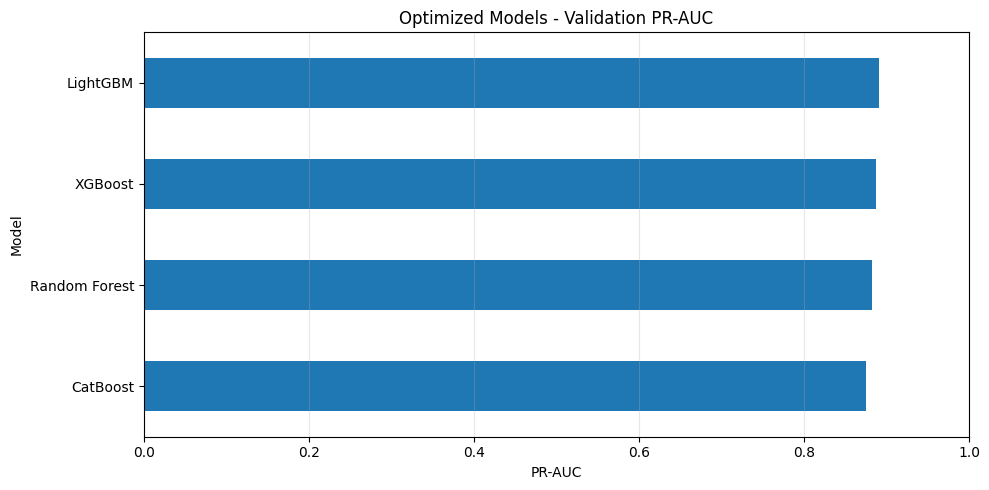

In [25]:
# Plot validation PR-AUC comparison
plt.figure(figsize=(10, 5))

comparison_df["validation_pr_auc"].sort_values().plot(kind="barh")

plt.title("Optimized Models - Validation PR-AUC")
plt.xlabel("PR-AUC")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 9.2 Threshold Analysis

# 9.2.1 Evaluate Precision and Recall Across Thresholds

In [26]:
from sklearn.metrics import (precision_score,recall_score,f1_score)

def evaluate_thresholds(y_true, y_probs, thresholds=None):

    if thresholds is None:
        thresholds = np.arange(0.05, 1.00, 0.01)

    results = []

    for threshold in thresholds:

        y_pred = (y_probs >= threshold).astype(int)

        results.append({
            "threshold": threshold,
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1_score": f1_score(
                y_true, y_pred, zero_division=0
            )
        })

    return pd.DataFrame(results)


print("Threshold evaluation function defined.")

Threshold evaluation function defined.


# 9.2.2 Compare Precision and Recall Across Models

In [27]:
# Store validation predictions for all models
model_probabilities = {
    "XGBoost": best_xgb_val_probs,
    "Random Forest": best_rf_val_probs,
    "LightGBM": best_lgb_val_probs,
    "CatBoost": best_cat_val_probs
}

# Evaluate each model across thresholds
threshold_results = {}

for model_name, probabilities in model_probabilities.items():

    results = evaluate_thresholds(y_val_xgb_best,probabilities)

    threshold_results[model_name] = results

    print(f"{model_name}: {len(results)} thresholds evaluated")

# Combine all model results
threshold_comparison_df = pd.concat(
    [
        results.assign(model=model_name)
        for model_name, results in threshold_results.items()
    ],
    ignore_index=True
)

# Save threshold comparison
threshold_path = REPORTS_DIR / "threshold_comparison_all_models.csv"

threshold_comparison_df.to_csv(threshold_path,index=False)

print("\nThreshold comparison completed.")
print("Saved to:", threshold_path)

threshold_comparison_df.head(10)

XGBoost: 95 thresholds evaluated
Random Forest: 95 thresholds evaluated
LightGBM: 95 thresholds evaluated
CatBoost: 95 thresholds evaluated

Threshold comparison completed.
Saved to: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\threshold_comparison_all_models.csv


,threshold,precision,recall,f1_score,model
0,0.05,0.108537,0.984026,0.195509,XGBoost
1,0.06,0.117681,0.982428,0.210185,XGBoost
2,0.07,0.126688,0.981629,0.224413,XGBoost
3,0.08,0.135138,0.980831,0.237547,XGBoost
4,0.09,0.142112,0.979233,0.248203,XGBoost
5,0.10,0.148462,0.979233,0.257834,XGBoost
6,0.11,0.154448,0.977636,0.266754,XGBoost
7,0.12,0.160414,0.976837,0.275575,XGBoost
8,0.13,0.166462,0.973642,0.284315,XGBoost
9,0.14,0.172790,0.972843,0.293459,XGBoost


# 9.2.3 Threshold Selection at Target Precision Levels

Find Optimal Thresholds for Each Model

In [29]:
# Define target precision levels
target_precisions = [0.70, 0.80, 0.85, 0.90]

threshold_selection_results = []

for model_name, results in threshold_results.items():

    for target_precision in target_precisions:

        # Keep thresholds satisfying target precision
        eligible = results[
            results["precision"] >= target_precision
        ]

        if not eligible.empty:

            # Select maximum recall
            best_row = eligible.loc[
                eligible["recall"].idxmax()
            ]

            threshold_selection_results.append({
                "model": model_name,
                "target_precision": target_precision,
                "threshold": best_row["threshold"],
                "achieved_precision": best_row["precision"],
                "recall": best_row["recall"],
                "f1_score": best_row["f1_score"]
            })

        else:

            threshold_selection_results.append({
                "model": model_name,
                "target_precision": target_precision,
                "threshold": np.nan,
                "achieved_precision": np.nan,
                "recall": np.nan,
                "f1_score": np.nan
            })

# Create comparison DataFrame
threshold_selection_df = pd.DataFrame(
    threshold_selection_results
)

display(threshold_selection_df.round(5))

# Save results
threshold_selection_path = (
    REPORTS_DIR / "threshold_calibration_comparison.csv"
)

threshold_selection_df.to_csv(threshold_selection_path,index=False)

print("\nThreshold selection results saved:", threshold_selection_path)

,model,target_precision,threshold,achieved_precision,recall,f1_score
0,XGBoost,0.70,0.92,0.70078,0.86422,0.77396
1,XGBoost,0.80,0.96,0.80311,0.82428,0.81356
2,XGBoost,0.85,0.98,0.88692,0.75799,0.81740
3,XGBoost,0.90,0.99,0.95044,0.68930,0.79907
4,Random Forest,0.70,0.44,0.70565,0.86741,0.77822
5,Random Forest,0.80,0.60,0.80000,0.81789,0.80885
6,Random Forest,0.85,0.69,0.85095,0.78435,0.81629
7,Random Forest,0.90,0.80,0.90149,0.72364,0.80284
8,LightGBM,0.70,0.92,0.71485,0.86502,0.78280
9,LightGBM,0.80,0.96,0.80266,0.81869,0.81060



Threshold selection results saved: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\threshold_calibration_comparison.csv


# 9.2.4 Visualize Precision-Recall Trade-offs

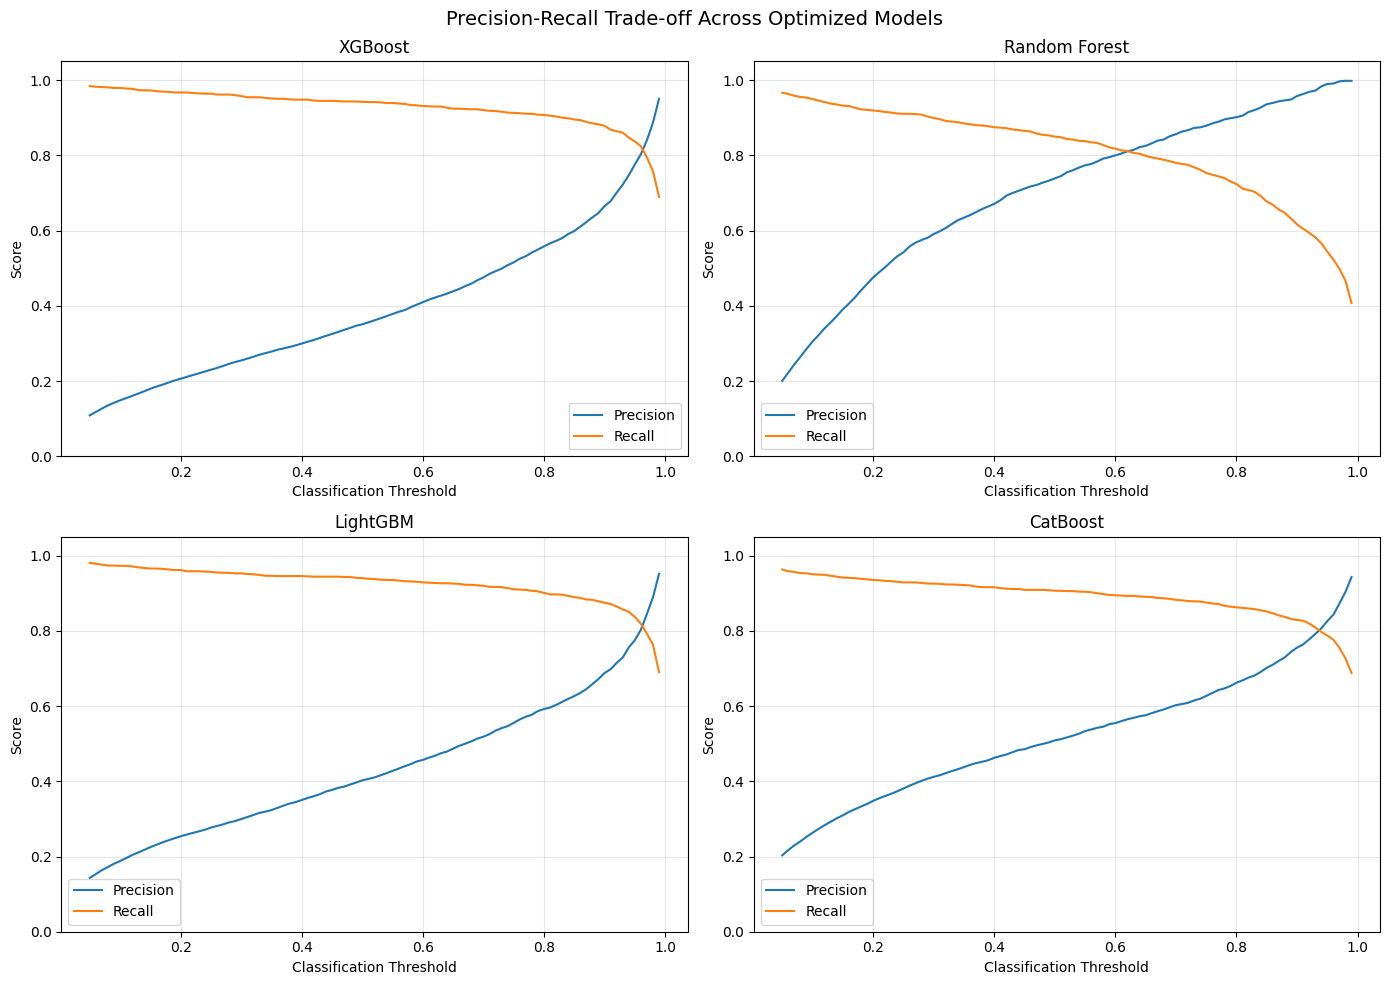

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (model_name, results) in zip(axes.flatten(),threshold_results.items()):

    ax.plot(results["threshold"],results["precision"],label="Precision")

    ax.plot(results["threshold"],results["recall"],label="Recall")

    ax.set_title(model_name)
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Precision-Recall Trade-off Across Optimized Models",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Confusion matrix at 80-85% Precision level

In [31]:
from sklearn.metrics import confusion_matrix

# Select target precision levels
selected_targets = [0.80, 0.85]

confusion_results = []

for model_name, probabilities in model_probabilities.items():

    model_thresholds = threshold_selection_df[
        threshold_selection_df["model"] == model_name
    ]

    for target in selected_targets:

        selected_row = model_thresholds[
            model_thresholds["target_precision"] == target
        ]

        if selected_row.empty or selected_row["threshold"].isna().all():
            continue

        threshold = selected_row.iloc[0]["threshold"]

        # Generate predictions
        predictions = (probabilities >= threshold).astype(int)

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val_xgb_best,
            predictions,
            labels=[0, 1]
        ).ravel()

        confusion_results.append({
            "model": model_name,
            "target_precision": target,
            "threshold": threshold,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "total_fraud_detected": tp,
            "legitimate_transactions_flagged": fp,
            "fraud_missed": fn
        })

# Create comparison DataFrame
confusion_comparison_df = pd.DataFrame(confusion_results)

display(confusion_comparison_df)

# Save report
confusion_path = REPORTS_DIR / "confusion_matrix_comparison.csv"

confusion_comparison_df.to_csv(
    confusion_path,
    index=False
)

print("\nConfusion matrix comparison saved:", confusion_path)

,model,target_precision,threshold,TP,FP,TN,FN,total_fraud_detected,legitimate_transactions_flagged,fraud_missed
0,XGBoost,0.80,0.96,1032,253,192996,220,1032,253,220
1,XGBoost,0.85,0.98,949,121,193128,303,949,121,303
2,Random Forest,0.80,0.60,1024,256,192993,228,1024,256,228
3,Random Forest,0.85,0.69,982,172,193077,270,982,172,270
4,LightGBM,0.80,0.96,1025,252,192997,227,1025,252,227
5,LightGBM,0.85,0.98,956,119,193130,296,956,119,296
6,CatBoost,0.80,0.94,998,239,193010,254,998,239,254
7,CatBoost,0.85,0.97,945,138,193111,307,945,138,307



Confusion matrix comparison saved: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\confusion_matrix_comparison.csv


## 10. Final Model Selection

### 10.1 Business-Oriented Selection Strategy

The fraud detection system aims to maximize fraud detection while controlling false-positive predictions and operational costs.

**Primary objectives:**
1. Maximize fraud detection recall.
2. Maintain a minimum precision target of 80%.
3. Evaluate 85% precision as a stricter alternative.
4. Minimize unnecessary manual reviews and legitimate transaction declines.
5. Consider model performance, probability calibration, and computational efficiency.

### 10.2 Key Findings

1. XGBoost achieved the highest fraud detection at the 80% target precision level, detecting 1,032 fraud cases.
2. LightGBM achieved the highest validation PR-AUC (0.89036) and ROC-AUC (0.99696).
3. At 85% target precision, LightGBM detected 956 fraudulent transactions with 119 false positives.
4. Random Forest achieved the highest fraud detection at 85% target precision, detecting 982 fraud cases, but generated more false alerts (172).
5. CatBoost showed comparatively lower validation PR-AUC.

### 10.3 Provisional Model Selection

**Selected primary candidate: LightGBM**

LightGBM is selected as the primary model candidate based on its validation ranking performance and competitive precision-recall trade-off.

- Initial operating threshold: 0.96
- Target precision: Approximately 80%
- Validation PR-AUC: 0.89036
- Validation ROC-AUC: 0.99696

XGBoost will be retained as the challenger model because of its strong fraud detection performance at the 80% precision target.

An 85% precision configuration will also be evaluated as a stricter alternative.

### 10.4 Final Evaluation Plan

Before production implementation:

1. Evaluate the selected LightGBM model on the untouched test dataset.
2. Compare test performance against validation performance.
3. Review precision, recall, PR-AUC, ROC-AUC, Brier score, and confusion matrix.
4. Confirm the operating threshold based on generalization performance and business requirements.
5. Save the finalized model and configuration for production implementation.

**Note:** The model and threshold remain provisional until final test evaluation.

# 11. Final Test Evaluation

Evaluate the selected LightGBM model on the untouched test dataset using the operating threshold selected on validation data.

In [32]:
# Select test features and target
X_test_final = test_df[velocity_features]
y_test_final = test_df[target_col]

# Check dataset dimensions
print("Test feature shape:", X_test_final.shape)
print("Test target shape:", y_test_final.shape)

# Check class distribution
print("\nTest class distribution:")
print(y_test_final.value_counts())

print("\nTest fraud rate:", round(y_test_final.mean() * 100, 4), "%")

Test feature shape: (194502, 13)
Test target shape: (194502,)

Test class distribution:
is_fraud
0    193369
1      1133
Name: count, dtype: int64

Test fraud rate: 0.5825 %


In [33]:
# Generate fraud probabilities
test_probs = best_lgb_model.predict_proba(X_test_final)[:, 1]

# Apply the threshold selected using validation data
FINAL_THRESHOLD = 0.96

test_predictions = (test_probs >= FINAL_THRESHOLD).astype(int)

print("Predictions generated successfully!")

print("\nProbability statistics:")
print(pd.Series(test_probs).describe())

print("\nPredicted class distribution:")
print(pd.Series(test_predictions).value_counts())

Predictions generated successfully!

Probability statistics:
count    194502.000000
mean          0.019056
std           0.107747
min           0.000036
25%           0.000289
50%           0.000554
75%           0.001538
max           0.999843
dtype: float64

Predicted class distribution:
0    193339
1      1163
Name: count, dtype: int64


# 11.1 Evaluation Metrics

In [36]:
from sklearn.metrics import (precision_score,recall_score,f1_score,accuracy_score,
    average_precision_score,roc_auc_score,brier_score_loss,confusion_matrix)

# Calculate evaluation metrics
test_metrics = {
    "PR-AUC": average_precision_score(y_test_final, test_probs),
    "ROC-AUC": roc_auc_score(y_test_final, test_probs),
    "Precision": precision_score(y_test_final, test_predictions),
    "Recall": recall_score(y_test_final, test_predictions),
    "F1-Score": f1_score(y_test_final, test_predictions),
    "Accuracy": accuracy_score(y_test_final, test_predictions),
    "Brier Score": brier_score_loss(y_test_final, test_probs)
}

# Display metrics
print("LightGBM - Test Evaluation Metrics")
print("-" * 40)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.6f}")

LightGBM - Test Evaluation Metrics
----------------------------------------
PR-AUC: 0.882989
ROC-AUC: 0.997122
Precision: 0.791917
Recall: 0.812886
F1-Score: 0.802265
Accuracy: 0.997666
Brier Score: 0.006973


Test Confusion Matrix Results
-----------------------------------
True Positives (TP):  921
False Positives (FP): 242
True Negatives (TN):  193127
False Negatives (FN): 212


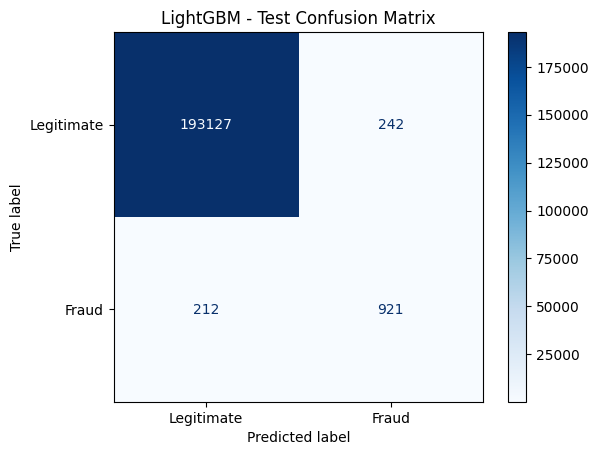

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test_final, test_predictions)

tn, fp, fn, tp = cm.ravel()

print("Test Confusion Matrix Results")
print("-" * 35)
print(f"True Positives (TP):  {tp}")
print(f"False Positives (FP): {fp}")
print(f"True Negatives (TN):  {tn}")
print(f"False Negatives (FN): {fn}")

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Legitimate", "Fraud"])

disp.plot(cmap="Blues", values_format="d")
plt.title("LightGBM - Test Confusion Matrix")
plt.show()

In [38]:
# Create confusion matrix DataFrame
cm_df = pd.DataFrame(cm,index=["Actual_Legitimate", "Actual_Fraud"],columns=["Predicted_Legitimate", "Predicted_Fraud"])

# Save confusion matrix locally
cm_path = REPORTS_DIR / "lightgbm_test_confusion_matrix.csv"
cm_df.to_csv(cm_path)

# Log final test evaluation in MLflow
with mlflow.start_run(run_name="LightGBM_Final_Test_Evaluation"):

    # Log model selection details
    mlflow.log_params({
        "selected_model": "LightGBM",
        "operating_threshold": FINAL_THRESHOLD,
        "feature_set": "static_plus_velocity",
        "evaluation_dataset": "test"
    })

    # Log test metrics
    mlflow.log_metrics({
        f"test_{metric.lower().replace('-', '_').replace(' ', '_')}": float(value)
        for metric, value in test_metrics.items()
    })

    # Log confusion matrix counts
    mlflow.log_metrics({
        "test_true_positives": int(tp),
        "test_false_positives": int(fp),
        "test_true_negatives": int(tn),
        "test_false_negatives": int(fn)
    })

    # Upload confusion matrix CSV
    mlflow.log_artifact(str(cm_path))

print("Final test evaluation logged successfully in MLflow.")
print("Confusion matrix saved:", cm_path)

🏃 View run LightGBM_Final_Test_Evaluation at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2/runs/854595a66bc04c44a777145351423e65
🧪 View experiment at: https://dagshub.com/krishnagupta96321/Sentinel-risk-engine.mlflow/#/experiments/2
Final test evaluation logged successfully in MLflow.
Confusion matrix saved: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\reports\lightgbm_test_confusion_matrix.csv
